# 02 Virtual tier (V): the ideal forward pass, step by step

Tier V is the math with nothing physical in it: unit delays, exact ternary sums, exact $\tanh$, float32. It reproduces the torch evaluation of the trained model to $2\times10^{-6}$ in the logits (M1 acceptance), and it is the **reference** for every "agreement", "KL" and "delta vs V" number in this project.

**Layer** (causal, zeros before $n=0$):

$$u_o[n]=\sum_{i,k}W_{o,i,k}\,x_i[n-k\,d],\qquad y_o[n]=g_o\tanh\!\Big(\frac{u_o[n]+b_o}{V_{sat}}\Big)$$

**Readout:** $f_o=\frac1T\sum_n y_o^{(3)}[n]$ (the RC pool), $z=W_r f+b_r$, $p=\mathrm{softmax}(z)$.

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")
from dlnn.tiers import virtual
from dlnn.tiers.common import softmax
model = run.model
EX = 6      # test example to walk through
y_true = int(run.labels[EX]); snr = float(run.snr[EX]); cls = run.classes
x = run.x_test[EX:EX + 1]
print(f"example {EX}: true class {cls[y_true]}, SNR {snr:.0f} dB, x shape {x.shape}")

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000
example 6: true class QPSK, SNR 5 dB, x shape (1, 2, 128)


### Step 1. The input lines

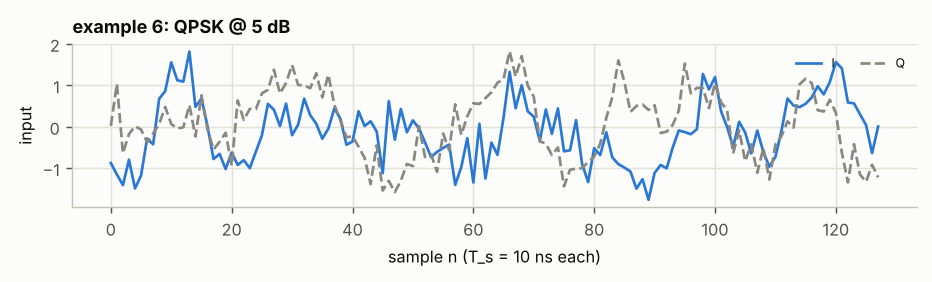

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 2.2))
ax.plot(x[0, 0], color=TIER_COL["light"]["V"], label="I"); ax.plot(x[0, 1], color=INK["light"]["muted"], ls="--", label="Q")
ax.set_xlabel("sample n (T_s = 10 ns each)"); ax.set_ylabel("input"); ax.legend(ncol=2, fontsize=7); ax.set_title(f"example {EX}: {cls[y_true]} @ {snr:.0f} dB")
fig.tight_layout(); nb.show_fig(fig)

### Step 2. One output unit of layer 1, tap by tap
Each non-zero tap contributes $\pm$ the input line delayed by $k\,d$ samples (a coax of length $k\,d\,T_s\,v_p$); the combiner adds them to give $u$.

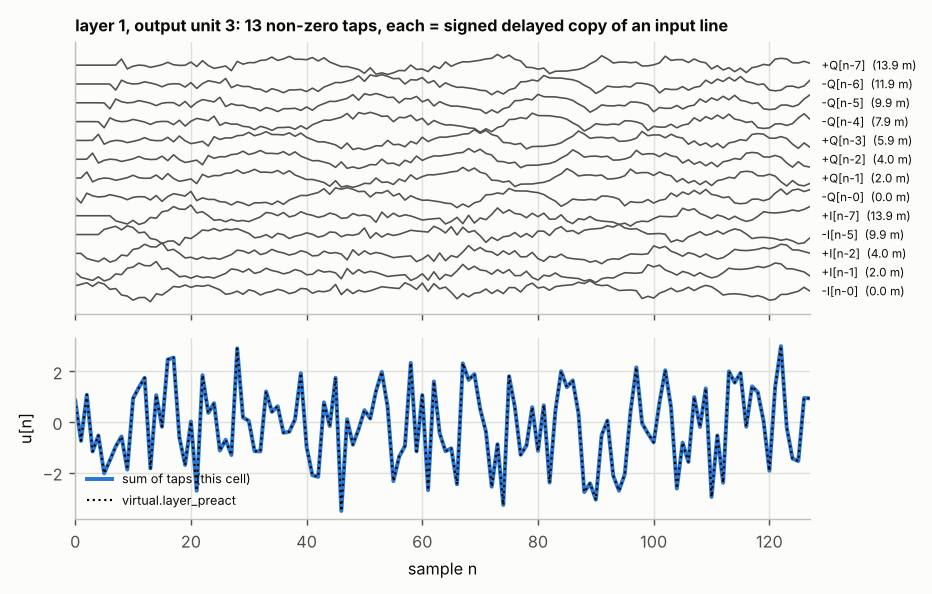

max |difference| vs the library implementation: 5.364418029785156e-07


In [3]:
ly = model.layers[0]
o = int(np.argmax((ly.W != 0).sum(axis=(1, 2))))             # the unit with the most taps, for a busy picture
xin = x[0] * model.input_scale
taps = [(i, k, int(ly.W[o, i, k])) for i in range(2) for k in range(ly.W.shape[2]) if ly.W[o, i, k] != 0]
T = xin.shape[1]; u = np.zeros(T)
fig, axs = plt.subplots(2, 1, figsize=(7.2, 4.6), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
for j, (i, k, w) in enumerate(taps):
    sh = np.zeros(T); sh[k * ly.dilation:] = xin[i, :T - k * ly.dilation]
    u += w * sh
    axs[0].plot(w * sh + 3.2 * j, lw=0.9, color=INK["light"]["sec"])
    axs[0].text(T + 1, 3.2 * j, f"{'+' if w > 0 else '-'}{'IQ'[i]}[n-{k * ly.dilation}]  ({k * ly.dilation * 1.98:.1f} m)", fontsize=6.5, va="center", clip_on=False)
axs[0].set_yticks([]); axs[0].set_xlim(0, T - 1); axs[0].set_title(f"layer 1, output unit {o}: {len(taps)} non-zero taps, each = signed delayed copy of an input line", fontsize=9)
ref = virtual.layer_preact(x * model.input_scale, ly)[0, o]
axs[1].plot(u, color=TIER_COL["light"]["V"], lw=2.2, label="sum of taps (this cell)"); axs[1].plot(ref, "k:", lw=1.2, label="virtual.layer_preact")
axs[1].set_xlabel("sample n"); axs[1].set_ylabel("u[n]"); axs[1].legend(fontsize=7)
fig.tight_layout(); nb.show_fig(fig)
print("max |difference| vs the library implementation:", float(np.abs(u - ref).max()))

### Step 3. The saturating amplifier (diff pair): $y=g\tanh((u+b)/V_{sat})$

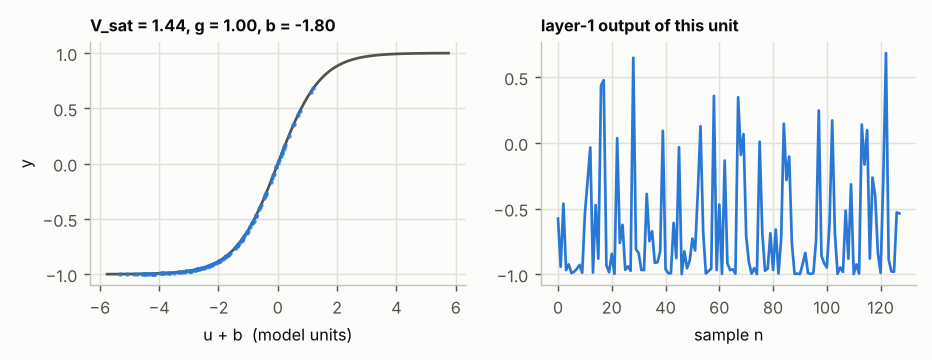

matches virtual.layer_forward: True


In [4]:
b, vs, g = float(ly.bias[o]), float(ly.vsat), float(ly.gain[o])
yo = g * np.tanh((u + b) / vs)
zz = np.linspace(-4 * vs, 4 * vs, 300)
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
axs[0].plot(zz, g * np.tanh(zz / vs), color=INK["light"]["sec"]); axs[0].plot(u + b, yo, ".", ms=3, color=TIER_COL["light"]["V"], alpha=0.7)
axs[0].set_xlabel("u + b  (model units)"); axs[0].set_ylabel("y"); axs[0].set_title(f"V_sat = {vs:.2f}, g = {g:.2f}, b = {b:+.2f}", fontsize=9)
axs[1].plot(yo, color=TIER_COL["light"]["V"]); axs[1].set_xlabel("sample n"); axs[1].set_title("layer-1 output of this unit", fontsize=9)
fig.tight_layout(); nb.show_fig(fig)
layers = virtual.forward_layers(model, x)
print("matches virtual.layer_forward:", float(np.abs(layers[0][0, o] - yo).max()) < 1e-5)

### Step 4. All three layers (dilations 1, 4, 16) and the pool

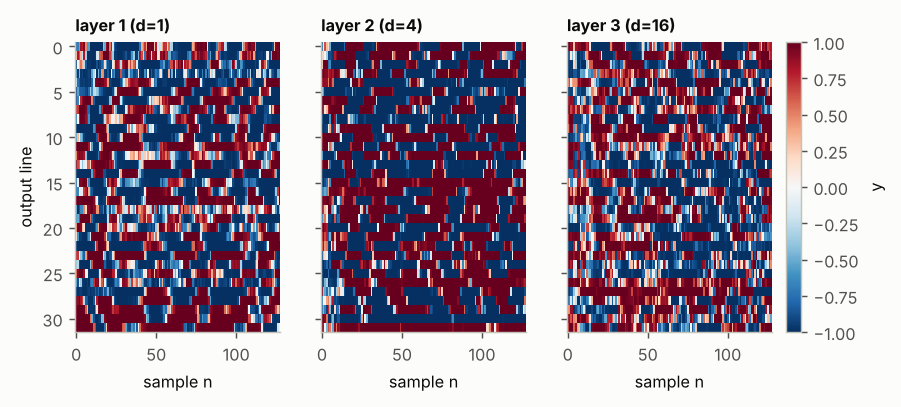

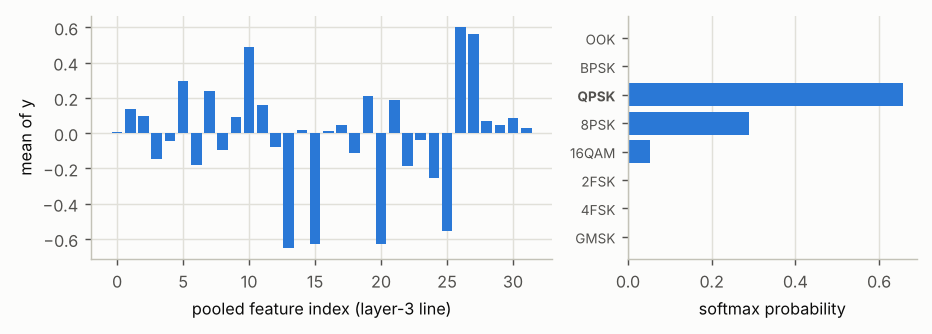

pred: QPSK | true: QPSK | max |p - stored V tier probs|: 8.940696716308594e-08


In [5]:
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.9), sharey=True)
for l, ax in enumerate(axs):
    im = ax.imshow(layers[l][0], aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest"); ax.grid(False)
    ax.set_title(f"layer {l + 1} (d={model.layers[l].dilation})", fontsize=9); ax.set_xlabel("sample n")
axs[0].set_ylabel("output line"); fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02).set_label("y")
nb.show_fig(fig)
feat = layers[-1][0].mean(axis=1)                     # RC average pool
logits = model.readout_W @ feat + model.readout_b
p = softmax(logits[None])[0]
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw={"width_ratios": [1.6, 1]})
axs[0].bar(range(len(feat)), feat, color=TIER_COL["light"]["V"]); axs[0].set_xlabel("pooled feature index (layer-3 line)"); axs[0].set_ylabel("mean of y")
axs[1].barh(range(8), p, color=TIER_COL["light"]["V"]); axs[1].set_yticks(range(8)); axs[1].set_yticklabels(cls, fontsize=7.5); axs[1].invert_yaxis()
axs[1].get_yticklabels()[y_true].set_fontweight("bold"); axs[1].set_xlabel("softmax probability"); axs[1].grid(axis="y", visible=False)
fig.tight_layout(); nb.show_fig(fig)
stored = run.res["V"].arrays["probs"][EX]
print("pred:", cls[int(p.argmax())], "| true:", cls[y_true], "| max |p - stored V tier probs|:", float(np.abs(p - stored).max()))

### Step 5. Cost in hardware terms, and the receptive field

In [6]:
rows = ["| layer | lines in -> out | K | d | longest tap | length (RG-58) | non-zero taps | ternary adds / sample |", "|---|---|---|---|---|---|---|---|"]
for l, ly_ in enumerate(model.layers):
    O, I, K = ly_.W.shape; nz = int((ly_.W != 0).sum()); d = ly_.dilation
    rows.append(f"| {l + 1} | {I} -> {O} | {K} | {d} | {(K - 1) * d * 10} ns | {(K - 1) * d * 1.98:.1f} m | {nz} of {ly_.W.size} | {nz} |")
nb.md("\n".join(rows))
print("receptive field:", 1 + sum((l.W.shape[2] - 1) * l.dilation for l in model.layers), "samples (>= 128 input samples)")
print("no multiplications in the taps: every weight is -1, 0 or +1, so a layer is additions and subtractions only.")

| layer | lines in -> out | K | d | longest tap | length (RG-58) | non-zero taps | ternary adds / sample |
|---|---|---|---|---|---|---|---|
| 1 | 2 -> 32 | 8 | 1 | 70 ns | 13.9 m | 321 of 512 | 321 |
| 2 | 32 -> 32 | 8 | 4 | 280 ns | 55.4 m | 4722 of 8192 | 4722 |
| 3 | 32 -> 32 | 8 | 16 | 1120 ns | 221.8 m | 4497 of 8192 | 4497 |

receptive field: 148 samples (>= 128 input samples)
no multiplications in the taps: every weight is -1, 0 or +1, so a layer is additions and subtractions only.


### Step 6. V on many examples (live) against the stored full-test-set result

live V on the first 500 test examples: accuracy 0.8580 (0.1 s)
stored V tier, same 500 examples: 0.8580 | whole test set (4000): 0.8628
identical predictions: True


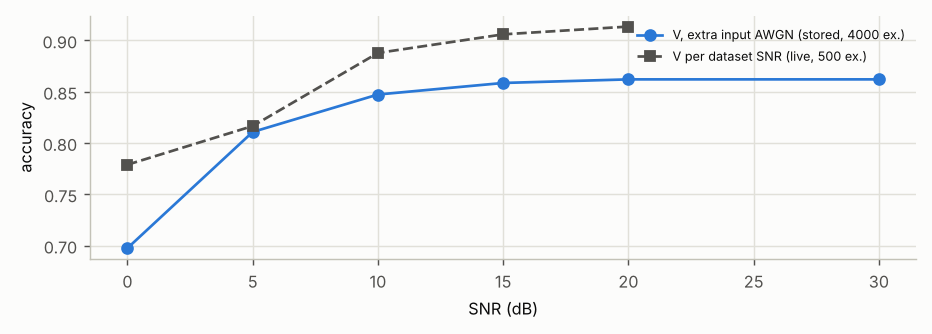

In [7]:
N = nb.n_subset(500)
t0 = time.time()
out = virtual.forward(model, run.x_test[:N])["out"]
pred = out.argmax(1)
acc = float((pred == run.labels[:N]).mean())
print(f"live V on the first {N} test examples: accuracy {acc:.4f} ({time.time() - t0:.1f} s)")
print(f"stored V tier, same {N} examples: {float((run.res['V'].arrays['pred'][:N] == run.labels[:N]).mean()):.4f} | whole test set (4000): {cmp['metric_matrix']['accuracy']['V']:.4f}")
print("identical predictions:", bool((pred == run.res['V'].arrays['pred'][:N]).all()))
sw = cmp["sweeps"]["snr_db"]["V"]
fig, ax = plt.subplots(figsize=(7.2, 2.6))
ax.plot(sw["values"], sw["accuracy"], marker="o", color=TIER_COL["light"]["V"], label="V, extra input AWGN (stored, 4000 ex.)")
snrs = run.snr; ax.plot(sorted(set(snrs)), [float((pred[snrs[:N] == s] == run.labels[:N][snrs[:N] == s]).mean()) for s in sorted(set(snrs))], "s--", color=INK["light"]["sec"], label=f"V per dataset SNR (live, {N} ex.)")
ax.set_xlabel("SNR (dB)"); ax.set_ylabel("accuracy"); ax.legend(fontsize=7); fig.tight_layout(); nb.show_fig(fig)